In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/new-york-city/nyc-parking-tickets/Parking_Violations_Issued_-_Fiscal_Year_2014__August_2013___June_2014_.csv
/kaggle/input/datasets/new-york-city/nyc-parking-tickets/Parking_Violations_Issued_-_Fiscal_Year_2015.csv
/kaggle/input/datasets/new-york-city/nyc-parking-tickets/Parking_Violations_Issued_-_Fiscal_Year_2016.csv
/kaggle/input/datasets/new-york-city/nyc-parking-tickets/Parking_Violations_Issued_-_Fiscal_Year_2017.csv


<div style="background: linear-gradient(135deg, #0B1F3A 0%, #1C3D6E 100%); padding: 30px; border-radius: 12px; border-left: 8px solid #F7B801; color: #FFFFFF; font-family: 'Segoe UI', sans-serif; box-shadow: 0 4px 12px rgba(0,0,0,0.15);">

# 🗽 NYC Parking Tickets Analysis <span style="color: #F7B801;">(FY 2017)</span>

**Exploratory Data Analysis (EDA)** • Temporal Patterns, Geographic Hotspots & Violation Profiles

<hr style="border: 0; border-top: 1px solid rgba(255,255,255,0.2); margin: 15px 0;">

**Author:** Muhammed Ali  |  **Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn  |  **Dataset:** NYC Dept. of Finance

</div>

<br>

<div style="background-color: #F8FAFC; padding: 20px; border-radius: 10px; border: 1px solid #E2E8F0; border-left: 5px solid #0B1F3A; color: #1E293B; font-family: 'Segoe UI', sans-serif;">

## 📌 Project Overview

New York City issues millions of parking tickets annually, generating hundreds of millions of dollars in revenue while managing urban congestion and enforcing traffic safety. This project performs a comprehensive **Exploratory Data Analysis (EDA)** on the **NYC Parking Violations dataset for Fiscal Year 2017** to uncover peak violation times, high-density boroughs, top violation types, and vehicle trends.

---

## ❓ Business Questions

1. **Temporal Patterns:** Which months, days of the week, and hours experience the highest volume of tickets?
2. **Geographic Hotspots:** Which NYC boroughs/counties have the highest concentration of parking violations?
3. **Top Violation Types:** What are the most frequent violation codes, and how do they vary by borough?
4. **Vehicle Profiles:** Which vehicle makes, body types, and plate types (Commercial vs. Passenger) receive the most tickets?
5. **Local vs. Out-of-State:** What proportion of tickets go to NY residents compared to out-of-state drivers?
6. **Enforcement Agencies:** Which agencies issue the majority of tickets, and how does their activity shift during the day?

</div>


<div style="background-color: #0B1F3A; padding: 12px 20px; border-radius: 8px; border-left: 6px solid #F7B801; color: #FFFFFF; font-family: 'Segoe UI', sans-serif;">
    <h2 style="margin: 0; font-size: 20px; color: #FFFFFF;">02 | Initial Data Inspection</h2>
</div>

#### import lap

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

#### Data loading

In [3]:
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

USE_SAMPLE = True
file_path = '/kaggle/input/datasets/new-york-city/nyc-parking-tickets/Parking_Violations_Issued_-_Fiscal_Year_2017.csv'

cols = [
    'Summons Number', 'Registration State', 'Plate Type', 'Issue Date',
    'Violation Code', 'Vehicle Body Type', 'Vehicle Make', 'Issuing Agency',
    'Violation Time', 'Violation County', 'Vehicle Color', 'Vehicle Year'
]

dtypes = {
    'Summons Number': 'int64',
    'Registration State': 'category',
    'Plate Type': 'category',
    'Violation Code': 'int16',
    'Vehicle Body Type': 'category',
    'Vehicle Make': 'category',
    'Issuing Agency': 'category',
    'Violation County': 'category',
    'Vehicle Color': 'category',
    'Vehicle Year': 'float32'
}

df = pd.read_csv(file_path, usecols=cols, dtype=dtypes, low_memory=False)

if USE_SAMPLE:
    df = df.sample(n=1_000_000, random_state=42).reset_index(drop=True)
    print("Loaded 1,000,000 RANDOM SAMPLE rows!")
else:
    print("Loaded FULL 2017 dataset!")

print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Memory Usage: {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
df.head()

Loaded 1,000,000 RANDOM SAMPLE rows!
Shape: 1,000,000 rows × 12 columns
Memory Usage: 131.42 MB


,Summons Number,Registration State,Plate Type,Issue Date,Violation Code,Vehicle Body Type,Vehicle Make,Issuing Agency,Violation Time,Violation County,Vehicle Color,Vehicle Year
0,7461974968,NC,PAS,10/28/2016,38,SUBN,TOYOT,T,1143A,Q,BLUE,0.0
1,4625799259,NY,PAS,10/25/2016,36,4DSD,TOYOT,V,0244P,BK,GR,2003.0
2,8479409009,NY,PAS,02/20/2017,31,SUBN,JEEP,T,0132P,NY,GY,2014.0
3,5096824962,NY,PAS,06/08/2017,7,4DSD,HONDA,V,0147P,QN,GY,2016.0
4,8473329958,NJ,PAS,01/18/2017,21,SUBN,HYUND,T,0848A,K,OTHER,0.0


In [4]:
df.tail()

,Summons Number,Registration State,Plate Type,Issue Date,Violation Code,Vehicle Body Type,Vehicle Make,Issuing Agency,Violation Time,Violation County,Vehicle Color,Vehicle Year
999995,4625607863,NY,PAS,10/24/2016,36,4DSD,NISSA,V,0732A,BK,BL,2012.0
999996,7497784602,OH,PAS,07/21/2016,21,4DSD,KIA,T,0840A,Q,GREY,0.0
999997,8156527677,NY,PAS,08/01/2016,24,4DSD,NISSA,T,1117A,K,BLACK,2009.0
999998,4006115283,NY,PAS,07/20/2016,5,SUBN,TOYOT,V,1205P,BX,GY,2013.0
999999,1405785202,99,PAS,09/24/2016,91,SUBN,TOW C,P,0320P,Q,BLACK,2004.0


### Data Quality Checklist 
- Data Information
- Data Shaping
- Missing Values
- Duplicates values
- Data describtion
- Unique Values

In [5]:
print("DATA INFORMATION")
df.info()

DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 12 columns):
 #   Column              Non-Null Count    Dtype   
---  ------              --------------    -----   
 0   Summons Number      1000000 non-null  int64   
 1   Registration State  1000000 non-null  category
 2   Plate Type          1000000 non-null  category
 3   Issue Date          1000000 non-null  object  
 4   Violation Code      1000000 non-null  int16   
 5   Vehicle Body Type   996048 non-null   category
 6   Vehicle Make        993154 non-null   category
 7   Issuing Agency      1000000 non-null  category
 8   Violation Time      999995 non-null   object  
 9   Violation County    996348 non-null   category
 10  Vehicle Color       985897 non-null   category
 11  Vehicle Year        1000000 non-null  float32 
dtypes: category(7), float32(1), int16(1), int64(1), object(2)
memory usage: 38.5+ MB


In [6]:

print(f'Data Shaping : {df.shape}')

Data Shaping : (1000000, 12)


In [7]:
print("Missing Values : ")
df.isna().sum()

Missing Values : 


Summons Number            0
Registration State        0
Plate Type                0
Issue Date                0
Violation Code            0
Vehicle Body Type      3952
Vehicle Make           6846
Issuing Agency            0
Violation Time            5
Violation County       3652
Vehicle Color         14103
Vehicle Year              0
dtype: int64

In [8]:
print('Duplicates Rows')
df.duplicated().sum()

Duplicates Rows


np.int64(0)

In [9]:
print('Describe for data numric: ')
df.describe().style.format('{:,.0f}')

Describe for data numric: 


,Summons Number,Violation Code,Vehicle Year
count,"1,000,000","1,000,000","1,000,000"
mean,"6,821,718,854",35,"1,577"
std,"2,316,589,858",19,827
min,"1,002,884,949",0,0
25%,"5,092,174,901",20,"1,999"
50%,"8,111,022,508",36,"2,008"
75%,"8,486,172,935",40,"2,014"
max,"8,585,550,016",99,"2,069"


In [10]:
print('Describe for data Categor.: ')
df.describe(include = 'category')

Describe for data Categor.: 


,Registration State,Plate Type,Vehicle Body Type,Vehicle Make,Issuing Agency,Violation County,Vehicle Color
count,1000000,1000000,996048,993154,1000000,996348,985897
unique,66,72,553,1259,14,10,745
top,NY,PAS,SUBN,FORD,T,NY,GY
freq,784737,740251,343295,117968,705095,317526,161531


In [11]:
print('Unique Values : ')
df.nunique()

Unique Values : 


Summons Number        1000000
Registration State         66
Plate Type                 72
Issue Date                830
Violation Code             97
Vehicle Body Type         553
Vehicle Make             1259
Issuing Agency             14
Violation Time           1522
Violation County           10
Vehicle Color             745
Vehicle Year               81
dtype: int64

In [12]:
df['Violation County'].value_counts()

Violation County
NY       317526
K        205264
Q        170309
BX       126405
BK        81919
QN        62172
ST        12779
R         11112
MN         8861
BRONX         1
KINGS         0
QNS           0
Name: count, dtype: int64

In [13]:
df['Vehicle Color'].value_counts()

Vehicle Color
GY       161531
WH       156024
BK       139712
WHITE    115805
BLACK     59057
          ...  
.             0
-I.           0
-GRY          0
-DGR          0
-,            0
Name: count, Length: 2367, dtype: int64

In [14]:
df['Violation Time'].value_counts()

Violation Time
0836A    2639
1140A    2483
1136A    2443
0906A    2417
0840A    2358
         ... 
1550P       1
0.51P       1
1626P       1
1315P       1
0003P       1
Name: count, Length: 1522, dtype: int64

In [15]:
(df['Registration State'] == '99').sum()

np.int64(3429)

<div style="background-color: #0B1F3A; padding: 12px 20px; border-radius: 8px; border-left: 6px solid #F7B801; color: #FFFFFF; font-family: 'Segoe UI', sans-serif;">
    <h2 style="margin: 0; font-size: 20px; color: #FFFFFF;">03 | Data Cleaning & Preprocessing</h2>
</div>

In [16]:
print('Remove duplicates : ')
df=df.drop_duplicates()
print('done')


Remove duplicates : 
done


In [17]:
print('change type of date:')
df['Issue Date'] = pd.to_datetime(df['Issue Date'], format = '%m/%d/%Y' , errors = 'coerce')
mindate = df['Issue Date'].min()
maxdate = df['Issue Date'].max()
print(f'this is min and max date before filtering : \nMin: {mindate}  \nMax:{maxdate} ')
row_befor  = len(df)
df = df[(df['Issue Date']>= '2016-07-01') &(df['Issue Date'] <='2017-06-30')].copy()
print(f"Rows removed (outside FY 2017): {row_befor - len(df):,}")
print("After filtering  -> Min:", mindate, "| Max:", maxdate)

change type of date:
this is min and max date before filtering : 
Min: 1990-08-27 00:00:00  
Max:2063-11-15 00:00:00 
Rows removed (outside FY 2017): 24,162
After filtering  -> Min: 1990-08-27 00:00:00 | Max: 2063-11-15 00:00:00


In [18]:
print('Handling Violation Time')
time_str = df['Violation Time'].astype(str).str.strip() + 'M'
parsed_time = pd.to_datetime(time_str, format='%I%M%p', errors='coerce')

df['Violation Hour'] = parsed_time.dt.hour

print('After change : ')
df['Violation Hour'].value_counts()

Handling Violation Time
After change : 


Violation Hour
9.0     106819
11.0    102879
13.0     97592
8.0      91444
12.0     89809
10.0     88437
14.0     82089
15.0     55167
16.0     52869
7.0      48369
17.0     38068
6.0      21879
18.0     19840
21.0     10818
20.0      9660
1.0       8696
22.0      8082
5.0       7710
2.0       7357
3.0       5888
23.0      5544
19.0      5332
0.0       3414
4.0       2647
Name: count, dtype: int64

In [19]:
print('Handle Violation county : ')
county_change= {
    'NY': 'Manhattan', 'MN': 'Manhattan',
    'K': 'Brooklyn',   'BK': 'Brooklyn',
    'Q': 'Queens',     'QN': 'Queens',
    'BX': 'Bronx',
    'R': 'Staten Island', 'ST': 'Staten Island'
}
df['Violation County'] = df['Violation County'].map(county_change).fillna('Unknown').astype('category')

print(df['Violation County'].value_counts())


Handle Violation county : 
Violation County
Manhattan        320805
Brooklyn         278631
Queens           226652
Bronx            123243
Staten Island     23078
Unknown            3429
Name: count, dtype: int64


In [20]:
print("Handle Vehicle Color : ")

color_change = {
    'WH': 'White', 'WHITE': 'White', 'WHT': 'White', 'WT': 'White',
    'GY': 'Gray', 'GRAY': 'Gray', 'GREY': 'Gray', 'GRY': 'Gray',
    'BK': 'Black', 'BLACK': 'Black', 'BLK': 'Black', 'BLAC': 'Black',
    'BL': 'Blue', 'BLUE': 'Blue', 'BLU': 'Blue', 'LTBL': 'Blue', 'DKBL': 'Blue',
    'RD': 'Red', 'RED': 'Red', 'MR': 'Red', 'MAROON': 'Red',
    'SILVE': 'Silver', 'SL': 'Silver', 'SIL': 'Silver', 'SILVER': 'Silver', 'SILVR': 'Silver',
    'GR': 'Green', 'GREEN': 'Green', 'GN': 'Green', 'GRN': 'Green',
    'BR': 'Brown', 'BROWN': 'Brown', 'BRN': 'Brown', 'TAN': 'Brown', 'TN': 'Brown',
    'YW': 'Yellow', 'YELLO': 'Yellow', 'YL': 'Yellow', 'GL': 'Gold', 'GOLD': 'Gold',
    'OR': 'Orange', 'ORANG': 'Orange'
}
df['Vehicle Color'] = df['Vehicle Color'].map(color_change).fillna("Other")

print(df['Vehicle Color'].value_counts())


Handle Vehicle Color : 
Vehicle Color
White     270831
Gray      201417
Black     201349
Blue       78163
Red        58700
Brown      49490
Other      36771
Green      28446
Silver     26986
Yellow     12118
Gold        8751
Orange      2816
Name: count, dtype: int64


In [21]:
print('Handling Vehicle Year : ')

invalidYears = (df['Vehicle Year']< 1970 )|(df['Vehicle Year'] >= 2018)
print(f'invaled year :{invalidYears.sum()} ')
df.loc[invalidYears , 'Vehicle Year' ] = np.nan 
minyear = df['Vehicle Year'].min()
maxyear = df['Vehicle Year'].max()

print(f'Min Year : {minyear}')
print(f'Max Year : {maxyear}')




Handling Vehicle Year : 
invaled year :211640 
Min Year : 1970.0
Max Year : 2017.0


In [22]:
print('Handling Registration State : ')

df['Registration State'] = df['Registration State'].astype(str).str.strip().replace({'nan':'Unknown'}).astype('category')

print(df['Registration State'].value_counts().head())

Handling Registration State : 
Registration State
NY    765652
NJ     83812
PA     25665
FL     12958
CT     12851
Name: count, dtype: int64


In [23]:
print('Handling all missing values in this columns : ')
cols = ['Vehicle Make', 'Vehicle Body Type', 'Plate Type', 'Issuing Agency']
for col in cols:
    df[col] = df[col].astype(str).replace({'nan': 'Unknown'}).astype('category')
print('Done')

Handling all missing values in this columns : 
Done


In [24]:
df.head(10)

,Summons Number,Registration State,Plate Type,Issue Date,Violation Code,Vehicle Body Type,Vehicle Make,Issuing Agency,Violation Time,Violation County,Vehicle Color,Vehicle Year,Violation Hour
0,7461974968,NC,PAS,2016-10-28,38,SUBN,TOYOT,T,1143A,Queens,Blue,NaN,11.0
1,4625799259,NY,PAS,2016-10-25,36,4DSD,TOYOT,V,0244P,Brooklyn,Green,2003.0,14.0
2,8479409009,NY,PAS,2017-02-20,31,SUBN,JEEP,T,0132P,Manhattan,Gray,2014.0,13.0
3,5096824962,NY,PAS,2017-06-08,7,4DSD,HONDA,V,0147P,Queens,Gray,2016.0,13.0
4,8473329958,NJ,PAS,2017-01-18,21,SUBN,HYUND,T,0848A,Brooklyn,Other,NaN,8.0
5,7445974120,NY,PAS,2016-08-29,70,4DSD,LEXUS,T,0149P,Queens,Brown,2014.0,13.0
6,7773195729,AL,PAS,2016-08-06,40,4DSD,NISSA,T,0514A,Bronx,Black,NaN,5.0
7,7503185934,NY,PAS,2016-11-04,20,SUBN,TOYOT,T,0213P,Brooklyn,Gray,2006.0,14.0
8,7492349075,NY,COM,2016-08-09,14,VAN,FRD,T,0948A,Manhattan,White,2008.0,9.0
9,5093091753,NJ,PAS,2016-08-22,7,WAGO,FORD,V,0132P,Brooklyn,Black,2016.0,13.0


<div style="background-color: #0B1F3A; padding: 12px 20px; border-radius: 8px; border-left: 6px solid #F7B801; color: #FFFFFF; font-family: 'Segoe UI', sans-serif;">
    <h2 style="margin: 0; font-size: 20px; color: #FFFFFF;">04 | Feature Engineering</h2>
</div>

In [25]:
print(' Create Date cols(month , (day of week)): ')
df['Month'] = df['Issue Date'].dt.month_name().astype('category')
df['Day_of_week'] = df['Issue Date'].dt.day_name().astype('category')
print('done')
df.columns

 Create Date cols(month , (day of week)): 
done


Index(['Summons Number', 'Registration State', 'Plate Type', 'Issue Date',
       'Violation Code', 'Vehicle Body Type', 'Vehicle Make', 'Issuing Agency',
       'Violation Time', 'Violation County', 'Vehicle Color', 'Vehicle Year',
       'Violation Hour', 'Month', 'Day_of_week'],
      dtype='object')

In [26]:
df['Day_of_week'].value_counts()

Day_of_week
Thursday     175940
Friday       172665
Tuesday      172519
Wednesday    166125
Monday       149568
Saturday      99701
Sunday        39320
Name: count, dtype: int64

In [27]:
print('day is weekend or not (In amric the weeken (Saturday , Sunday)) : ')
df['Is_Weekend'] = np.where(df['Issue Date'].dt.dayofweek >= 5, 'Weekend', 'Weekday')
df['Is_Weekend'] = df['Is_Weekend'].astype('category')
print(df['Is_Weekend'].value_counts())
print('done')

day is weekend or not (In amric the weeken (Saturday , Sunday)) : 
Is_Weekend
Weekday    836817
Weekend    139021
Name: count, dtype: int64
done


In [28]:
print('Create Season : ')
month_to_season = {
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Spring',  4: 'Spring', 5: 'Spring',
    6: 'Summer',  7: 'Summer', 8: 'Summer',
    9: 'Fall',   10: 'Fall',  11: 'Fall'
}
df['Season'] = df['Issue Date'].dt.month.map(month_to_season).astype('category')
print(df['Season'].value_counts())
print('done')

Create Season : 
Season
Spring    267104
Fall      261908
Winter    229472
Summer    217354
Name: count, dtype: int64
done


In [29]:
print('Time_of_day : '  )
df['Time_of_day'] = pd.cut(
    df['Violation Hour'],
    bins=[-1, 5, 11, 17, 23],
    labels=['Night (0-5)', 'Morning (6-11)', 'Afternoon (12-17)', 'Evening (18-23)']
)
print(df['Time_of_day'].value_counts())
print('done')

Time_of_day : 
Time_of_day
Morning (6-11)       459827
Afternoon (12-17)    415594
Evening (18-23)       59276
Night (0-5)           35712
Name: count, dtype: int64
done


In [30]:
print('Vehicle age : ')
df['Vehicle_age'] = (2017-df['Vehicle Year']).clip(lower=0)
print(' created done')

Vehicle age : 
 created done


In [31]:
df['Plate Type'].value_counts()

Plate Type
PAS    722049
COM    165964
OMT     40559
OMS      9858
SRF      8206
        ...  
CCK         1
LMC         1
JSC         1
OMO         1
USC         1
Name: count, Length: 72, dtype: int64

In [32]:
print('Plate_Category : \n')
plate_conditions = [
    df['Plate Type'] == 'PAS',
    df['Plate Type'] =='COM'
]
df['Plate_category'] = np.select(plate_conditions,['Passenger','Commercial'],default = 'Other')
df['Plate_category'] = df['Plate_category'].astype('category')
print(df['Plate_category'].value_counts())
print('done')

Plate_Category : 

Plate_category
Passenger     722049
Commercial    165964
Other          87825
Name: count, dtype: int64
done


In [33]:
print('Division of the states : ')

state_conditions = [
    df['Registration State'] == 'NY',
    df['Registration State'] == 'Unknown'
]
df['Is_NY_State'] = np.select(state_conditions, ['NY (Local)', 'Unknown'], default='Out-of-State')
df['Is_NY_State'] = df['Is_NY_State'].astype('category')

print(df['Is_NY_State'].value_counts())
print('done')

Division of the states : 
Is_NY_State
NY (Local)      765652
Out-of-State    210186
Name: count, dtype: int64
done


In [34]:
# with searching
print('Violation Description : ')
top_violations_map = {
    21: 'No Parking (Street Cleaning)',
    36: 'School Zone Speeding',
    38: 'Expired Parking Meter',
    14: 'No Standing (Day/Time Limits)',
    20: 'No Parking (Day/Time Limits)',
    46: 'Double Parking',
    71: 'Expired Inspection Sticker',
    7:  'Failure to Stop at Red Light',
    40: 'Fire Hydrant',
    19: 'Bus Stop'
}
df['Violation_Description'] = (
    df['Violation Code']
    .map(top_violations_map)
    .fillna('Other Violations')
    .astype('category')
)
print(df['Violation_Description'].value_counts())
print("done")

Violation Description : 
Violation_Description
Other Violations                 258091
No Parking (Street Cleaning)     138796
School Zone Speeding             124328
Expired Parking Meter             97158
No Standing (Day/Time Limits)     81714
No Parking (Day/Time Limits)      56622
Double Parking                    53914
Expired Inspection Sticker        48034
Fire Hydrant                      47389
Failure to Stop at Red Light      43379
Bus Stop                          26413
Name: count, dtype: int64
done


### Finished Features

<div style="background-color: #0B1F3A; padding: 12px 20px; border-radius: 8px; border-left: 6px solid #F7B801; color: #FFFFFF; font-family: 'Segoe UI', sans-serif;">
    <h2 style="margin: 0; font-size: 20px; color: #FFFFFF;">05 | Exploratory Data Analysis (EDA) & Visualizations</h2>
</div>

### Temporal Patterns : Which month, days , week, and hours experience the highest volume of tickets?

In [35]:
df.columns

Index(['Summons Number', 'Registration State', 'Plate Type', 'Issue Date',
       'Violation Code', 'Vehicle Body Type', 'Vehicle Make', 'Issuing Agency',
       'Violation Time', 'Violation County', 'Vehicle Color', 'Vehicle Year',
       'Violation Hour', 'Month', 'Day_of_week', 'Is_Weekend', 'Season',
       'Time_of_day', 'Vehicle_age', 'Plate_category', 'Is_NY_State',
       'Violation_Description'],
      dtype='object')

In [36]:
months = ['July', 'August', 'September', 'October', 'November', 'December',
             'January', 'February', 'March', 'April', 'May', 'June']
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

monthly_summary = (
    df.groupby('Month', observed=True)['Summons Number']
    .count()
    .reindex(months)
    .reset_index(name='Ticket_Count')
)
monthly_summary['Percentage '] = (monthly_summary['Ticket_Count'] / len(df) * 100).round(2)
print(" Monthly Violations")
display(monthly_summary)

 Monthly Violations


,Month,Ticket_Count,Percentage
0,July,64699,6.63
1,August,73684,7.55
2,September,88901,9.11
3,October,89861,9.21
4,November,83146,8.52
5,December,71926,7.37
6,January,81248,8.33
7,February,76298,7.82
8,March,89795,9.20
9,April,82768,8.48


In [37]:
daily_summary = (
    df.groupby('Day_of_week', observed=True)['Summons Number']
    .count()
    .reindex(days_order)
    .reset_index(name='Ticket_Count')
)
daily_summary['Percentage '] = (daily_summary['Ticket_Count'] / len(df) * 100).round(2)
print("Daily Violations")
display(daily_summary)

Daily Violations


,Day_of_week,Ticket_Count,Percentage
0,Monday,149568,15.33
1,Tuesday,172519,17.68
2,Wednesday,166125,17.02
3,Thursday,175940,18.03
4,Friday,172665,17.69
5,Saturday,99701,10.22
6,Sunday,39320,4.03


In [38]:
hourly_summary = (
    df.groupby('Violation Hour', observed=True)['Summons Number']
    .count()
    .reset_index(name='Ticket_Count')
)
hourly_summary['Percentage '] = (hourly_summary['Ticket_Count'] / len(df) * 100).round(2)
print("Top 10 Peak Hours ")
display(hourly_summary.sort_values('Ticket_Count', ascending=False).head(10))

Top 10 Peak Hours 


,Violation Hour,Ticket_Count,Percentage
9,9.0,106819,10.95
11,11.0,102879,10.54
13,13.0,97592,10.00
8,8.0,91444,9.37
12,12.0,89809,9.20
10,10.0,88437,9.06
14,14.0,82089,8.41
15,15.0,55167,5.65
16,16.0,52869,5.42
7,7.0,48369,4.96


In [39]:
day_time_pivot = pd.pivot_table(
    df,
    index='Day_of_week',
    columns='Time_of_day',
    values='Summons Number',
    aggfunc='count',
    observed=True,
    margins=True,          
    margins_name='Total'
).reindex(days_order + ['Total'])

print("Day of Week vs. Time of Day (Pivot Table)")
display(day_time_pivot)

Day of Week vs. Time of Day (Pivot Table)


Time_of_day,Night (0-5),Morning (6-11),Afternoon (12-17),Evening (18-23),Total
Day_of_week,,,,,
Monday,4051,73510,64650,7184,149395
Tuesday,4286,81527,76240,10061,172114
Wednesday,4932,73894,75921,10532,165279
Thursday,5662,83567,75519,10178,174926
Friday,5582,83653,71726,10550,171511
Saturday,6821,47658,36856,7102,98437
Sunday,4378,16018,14682,3669,38747
Total,35712,459827,415594,59276,970409


/tmp/ipykernel_16/1414388676.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


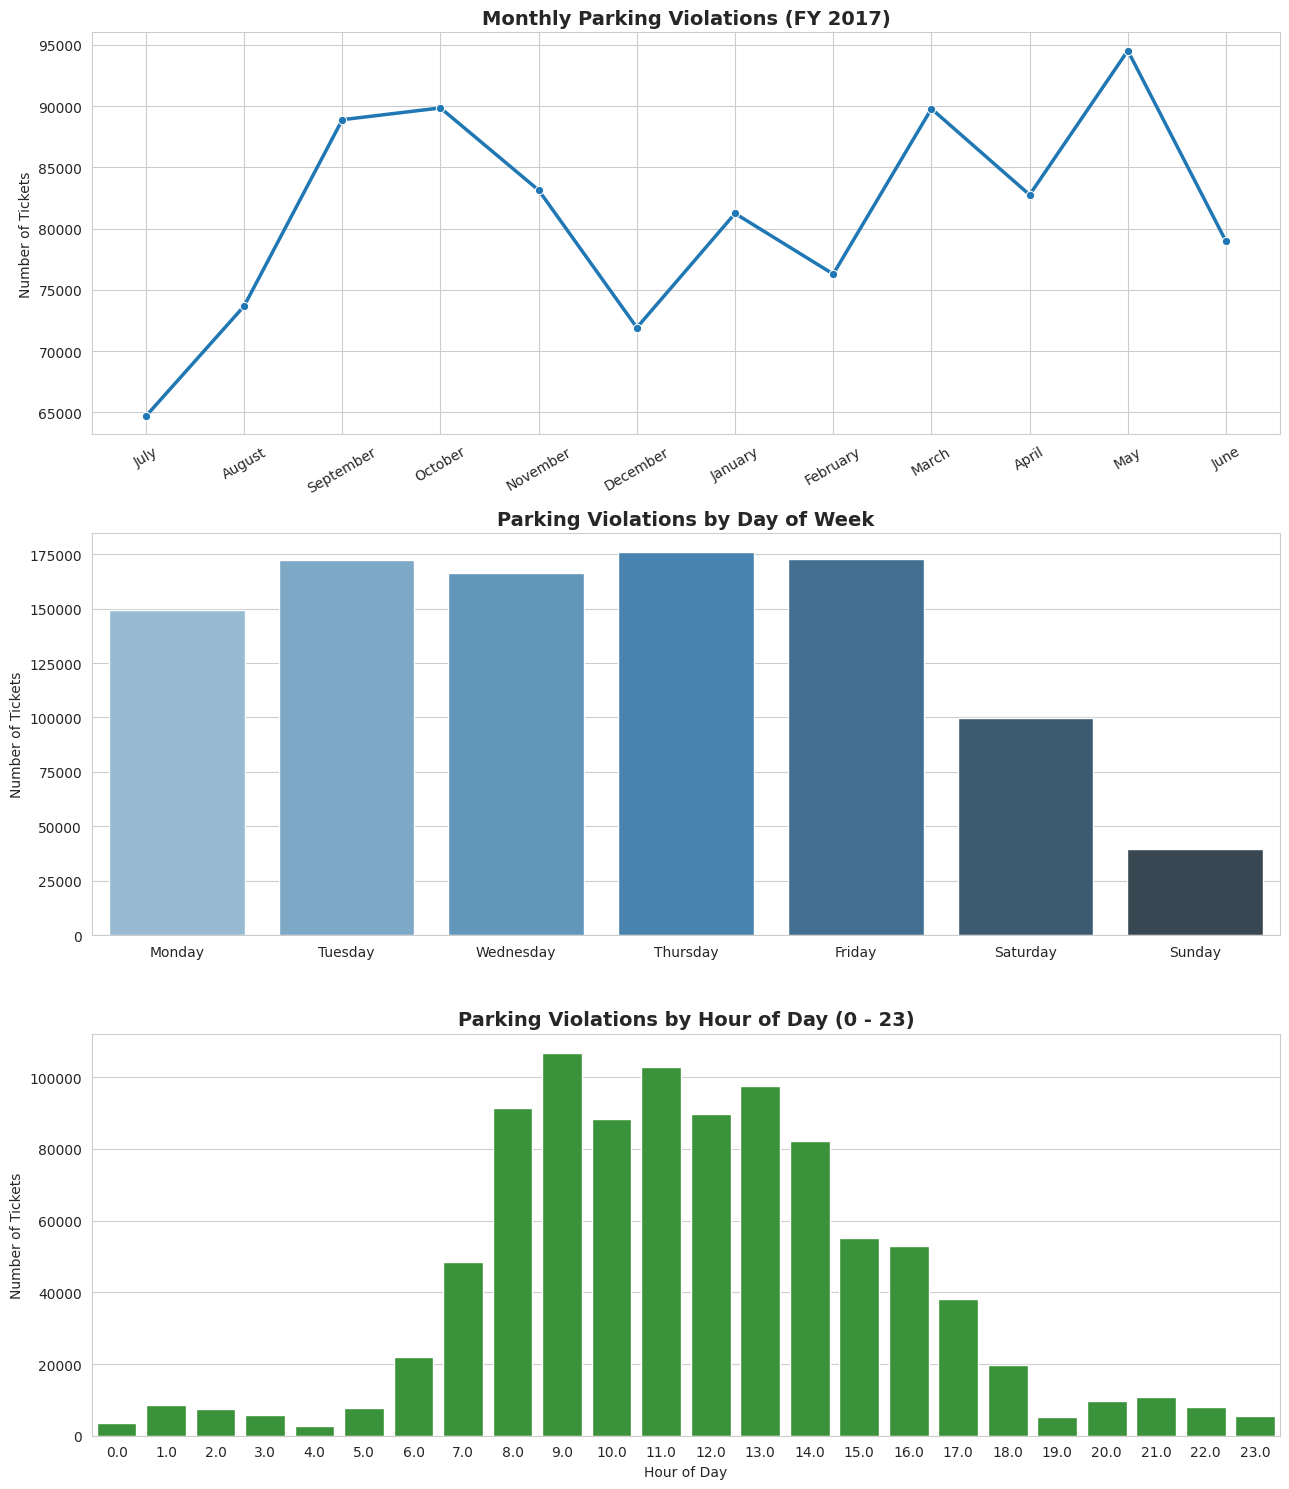

In [40]:
fig, axes = plt.subplots(3, 1, figsize=(13, 15))
# Monthly Trend Line Chart
sns.lineplot(
    data=monthly_summary, x='Month', y='Ticket_Count',
    marker='o', linewidth=2.5, color='#1f77b4', ax=axes[0]
)
axes[0].set_title('Monthly Parking Violations (FY 2017)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Number of Tickets')
axes[0].tick_params(axis='x', rotation=30)

#  Day of Week (Bar Chart) 
sns.barplot(
    data=daily_summary, x='Day_of_week', y='Ticket_Count',
    palette='Blues_d', ax=axes[1]
)
axes[1].set_title('Parking Violations by Day of Week', fontsize=14, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Number of Tickets')

# Hourly Distribution (Bar Chart) 
sns.barplot(
    data=hourly_summary, x='Violation Hour', y='Ticket_Count',
    color='#2ca02c', ax=axes[2]
)
axes[2].set_title('Parking Violations by Hour of Day (0 - 23)', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Hour of Day')
axes[2].set_ylabel('Number of Tickets')

plt.tight_layout()
plt.show()

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b> Monthly Trend: Ticket volume peaks in May (~95K), followed closely by October (~90K), March (~90K), and September (~89K). The lowest volumes occur in July (~65K) and December (~72K), reflecting summer vacations and the December holiday season when enforcement eases.
</div>

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b> Day of Week: Violations are heavily concentrated on weekdays (Monday–Friday), peaking on Thursday (~176K), followed closely by Friday (~173K) and Tuesday (~172K). Volume drops sharply over the weekend—falling to ~100K on Saturday and hitting its lowest point on Sunday (~39K) as many parking regulations are suspended.
</div>

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b> Peak Hours: Enforcement ramps up sharply at 7:00 AM (~48K) and reaches its peak window between 8:00 AM and 2:00 PM, with 9:00 AM (~107K) being the busiest single hour, followed by 11:00 AM (~103K) and 1:00 PM (~97K). Activity declines steadily after 2:00 PM and drops to minimal levels after 6:00 PM through the night.
</div>

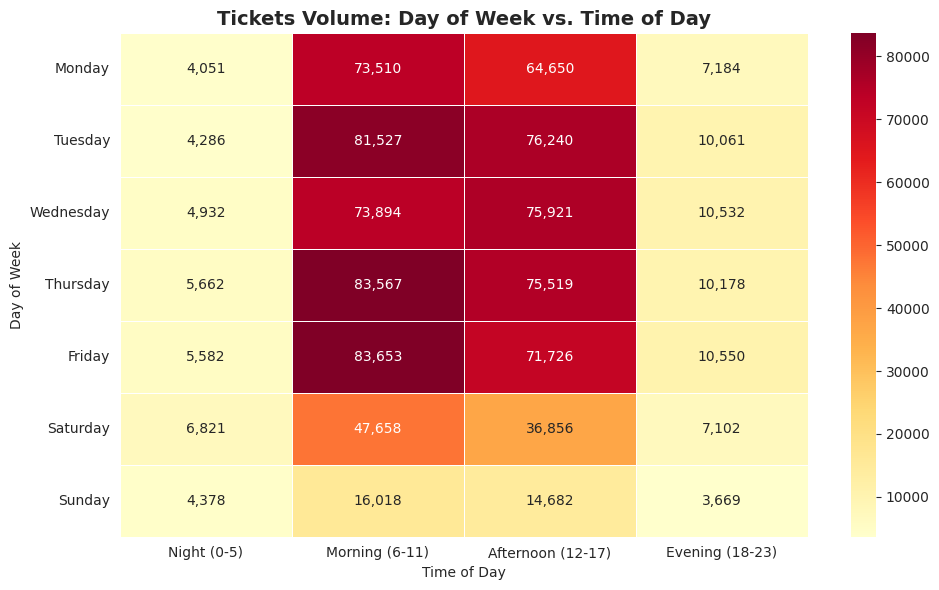

In [41]:
pivot_for_plot = day_time_pivot.drop(index='Total', columns='Total')

plt.figure(figsize=(10, 6))
sns.heatmap(pivot_for_plot, annot=True, fmt=',d', cmap='YlOrRd', linewidths=0.5)
plt.title('Tickets Volume: Day of Week vs. Time of Day', fontsize=14, fontweight='bold')
plt.xlabel('Time of Day')
plt.ylabel('Day of Week')
plt.tight_layout()
plt.show()

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>Day vs. Time of Day (Heatmap): The highest-risk parking window in NYC is weekday mornings (6:00–11:00)—specifically Friday (83,653), Thursday (83,567), and Tuesday (81,527)—followed closely by weekday afternoons (12:00–17:00), which peak on Tuesday (76,240) and Wednesday (75,921). Night (0–5) and Evening (18–23) remain consistently low throughout the entire week, with Sunday evening (3,669) recording the lowest volume overall.
</div>

### Geographic Hotspots: Which NYC boroughs/counties have the highest concentration of parking violations?

In [42]:
borough_summary = (
    df.groupby('Violation County', observed=True)['Summons Number']
    .count()
    .sort_values(ascending=False)
    .reset_index(name='Ticket_Count')
)
borough_summary['Percentage'] = (borough_summary['Ticket_Count'] / len(df) * 100).round(2)

print("Parking Violations by NYC Borough ")
display(borough_summary)

Parking Violations by NYC Borough 


,Violation County,Ticket_Count,Percentage
0,Manhattan,320805,32.87
1,Brooklyn,278631,28.55
2,Queens,226652,23.23
3,Bronx,123243,12.63
4,Staten Island,23078,2.36
5,Unknown,3429,0.35


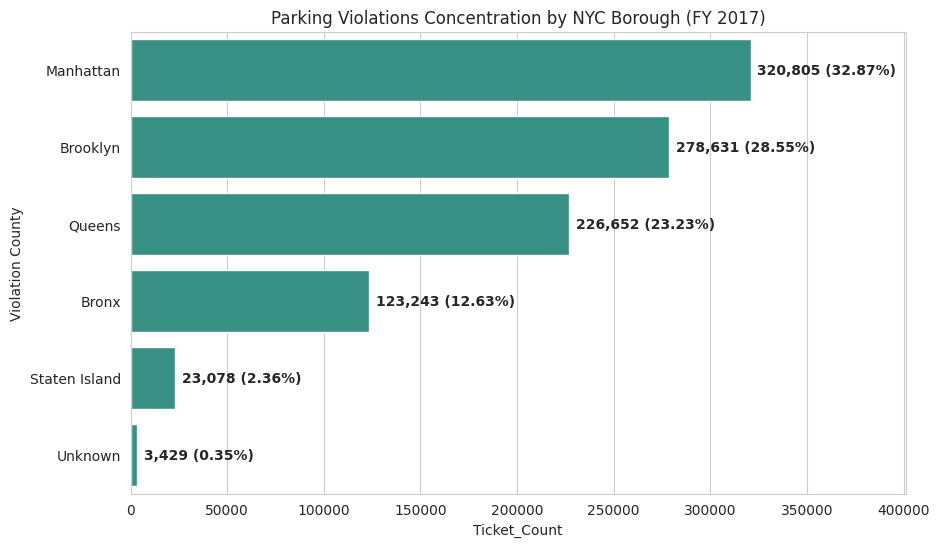

In [43]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=borough_summary, x='Ticket_Count', y='Violation County',
    order=borough_summary['Violation County'], color='#2a9d8f'
)

labels = [f"{c:,} ({p}%)" for c, p in zip(borough_summary['Ticket_Count'], borough_summary['Percentage'])]
ax.bar_label(ax.containers[0], labels=labels, padding=5, fontweight='bold')

plt.title('Parking Violations Concentration by NYC Borough (FY 2017)')
plt.xlim(0, borough_summary['Ticket_Count'].max() * 1.25)
plt.show()

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>Heavy Concentration in Top 3 Boroughs: Manhattan leads with 320,805 tickets (32.87%), followed closely by Brooklyn (278,631 | 28.55%) and Queens (226,652 | 23.23%). Together, these three boroughs account for 84.65% of all parking violations in NYC.
</div>

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>Lower-Volume Boroughs: The Bronx represents 12.63% (123,243 tickets), while Staten Island accounts for only 2.36% (23,078 tickets)—reflecting its more suburban, lower-density layout and greater availability of private parking. Unknown locations make up a negligible 0.35% (3,429 tickets).
</div>

In [44]:
borough_weekend_pivot = pd.pivot_table(
    df,
    index='Violation County',
    columns='Is_Weekend',
    values='Summons Number',
    aggfunc='count',
    observed=True
).reindex(borough_summary['Violation County'])
borough_weekend_pivot['Weekend_Share'] = (
    borough_weekend_pivot['Weekend'] /
    (borough_weekend_pivot['Weekday'] + borough_weekend_pivot['Weekend']) * 100
).round(2)
borough_weekend_pivot = borough_weekend_pivot.sort_values(by='Weekend_Share', ascending=False)
print("Borough Violations: Weekday vs. Weekend")
display(borough_weekend_pivot)

Borough Violations: Weekday vs. Weekend


Is_Weekend,Weekday,Weekend,Weekend_Share
Violation County,,,
Unknown,2787,642,18.72
Bronx,103664,19579,15.89
Manhattan,273751,47054,14.67
Queens,194024,32628,14.40
Brooklyn,242455,36176,12.98
Staten Island,20136,2942,12.75


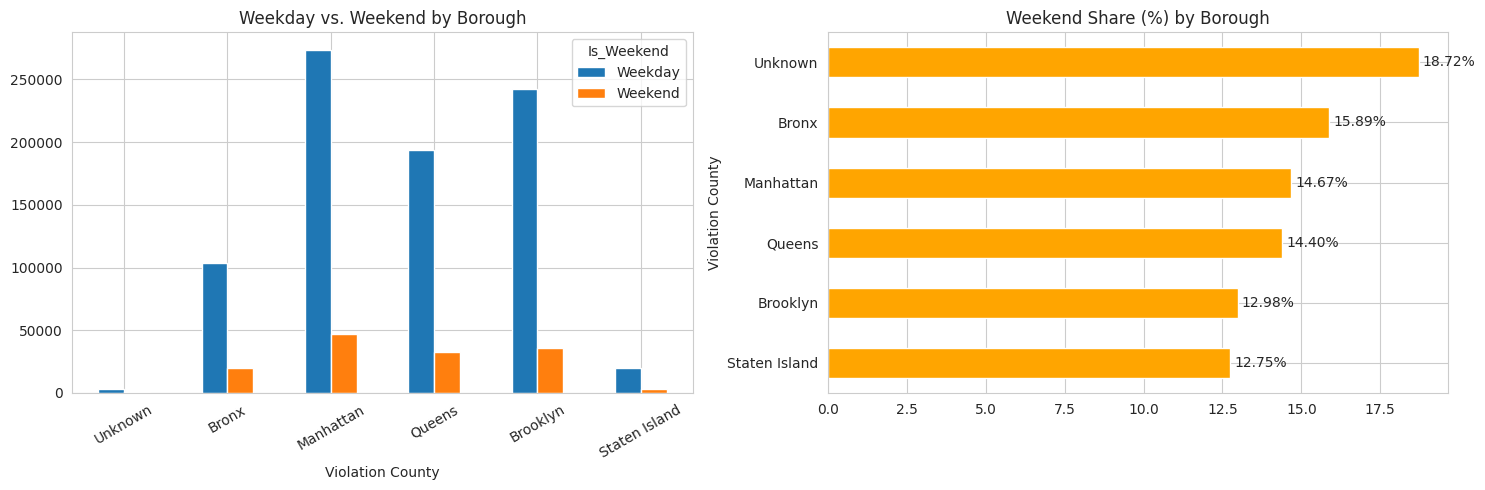

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

borough_weekend_pivot[['Weekday', 'Weekend']].plot(
    kind='bar', ax=axes[0], rot=30, title='Weekday vs. Weekend by Borough'
)

ax2 = borough_weekend_pivot['Weekend_Share'].sort_values().plot(
    kind='barh', ax=axes[1], color='orange', title='Weekend Share (%) by Borough'
)
ax2.bar_label(ax2.containers[0], fmt='%.2f%%', padding=3)

plt.tight_layout()
plt.show()

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>Weekday Dominance Across All Boroughs: In every borough, weekday violations vastly outnumber weekend violations, confirming that commercial activity and weekday commuting drive enforcement citywide.
</div>

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>Weekend Share Nuance: Excluding Unknown (18.72%), The Bronx has the highest proportion of weekend tickets (15.89%), followed by Manhattan (14.67%) and Queens (14.40%). Staten Island (12.75%) and Brooklyn (12.98%) see the sharpest relative drop-off over the weekend.
</div>

### Top Violation Types: What are the most frequent violation codes, and how do they vary by borough?

In [46]:
violation_summary = (
    df.groupby('Violation_Description', observed=True)['Summons Number']
    .count()
    .sort_values(ascending=False)
    .reset_index(name='Ticket_Count')
)
violation_summary['Percentage'] = (violation_summary['Ticket_Count'] / len(df) * 100).round(2)

print("Top Violation Types")
display(violation_summary)

Top Violation Types


,Violation_Description,Ticket_Count,Percentage
0,Other Violations,258091,26.45
1,No Parking (Street Cleaning),138796,14.22
2,School Zone Speeding,124328,12.74
3,Expired Parking Meter,97158,9.96
4,No Standing (Day/Time Limits),81714,8.37
5,No Parking (Day/Time Limits),56622,5.80
6,Double Parking,53914,5.52
7,Expired Inspection Sticker,48034,4.92
8,Fire Hydrant,47389,4.86
9,Failure to Stop at Red Light,43379,4.45


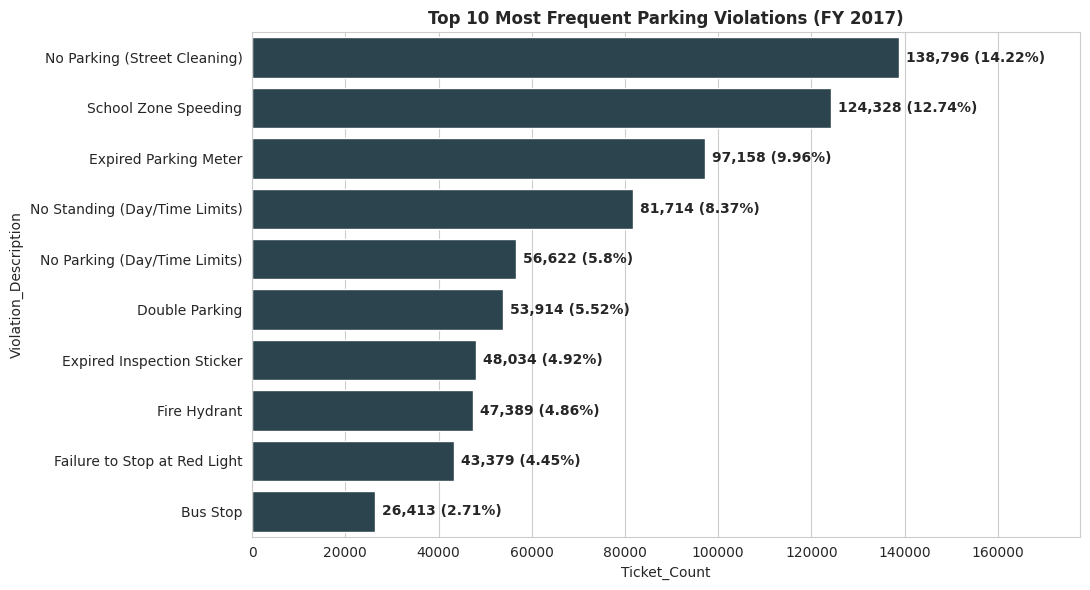

In [47]:
top10_plot = violation_summary[violation_summary['Violation_Description'] != 'Other Violations']

plt.figure(figsize=(11, 6))
ax = sns.barplot(
    data=top10_plot, x='Ticket_Count', y='Violation_Description',
    order=top10_plot['Violation_Description'], color='#264653'
)

labels = [f"{c:,} ({p}%)" for c, p in zip(top10_plot['Ticket_Count'], top10_plot['Percentage'])]
ax.bar_label(ax.containers[0], labels=labels, padding=5, fontweight='bold')

plt.title('Top 10 Most Frequent Parking Violations (FY 2017)', fontweight='bold')
plt.xlim(0, top10_plot['Ticket_Count'].max() * 1.28)
plt.tight_layout()
plt.show()

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>Top 3 Violations Dominate: No Parking (Street Cleaning) leads with 138,796 tickets (14.22%), followed by School Zone Speeding (124,328 | 12.74%) and Expired Parking Meter (97,158 | 9.96%). Together, the top 10 violations account for 73.55% of all tickets.
</div>

In [48]:
top_df = df[(df['Violation_Description'] != 'Other Violations') & (df['Violation County'] != 'Unknown')]

violation_borough_pivot = pd.pivot_table(
    top_df,
    index='Violation_Description',
    columns='Violation County',
    values='Summons Number',
    aggfunc='count',
    observed=True
).fillna(0).astype(int)

print("Top Violations by Borough")
display(violation_borough_pivot)

Top Violations by Borough


Violation County,Bronx,Brooklyn,Manhattan,Queens,Staten Island
Violation_Description,,,,,
Bus Stop,3526,6616,9793,6001,268
Double Parking,9104,10347,29217,4215,121
Expired Inspection Sticker,7305,14040,8794,14685,3167
Expired Parking Meter,11942,27006,28140,28472,1561
Failure to Stop at Red Light,4586,14983,2659,17726,3425
Fire Hydrant,7963,14952,13237,9982,964
No Parking (Day/Time Limits),8700,14127,18855,14137,569
No Parking (Street Cleaning),20973,59859,26525,30949,4
No Standing (Day/Time Limits),5668,14848,47554,12466,857


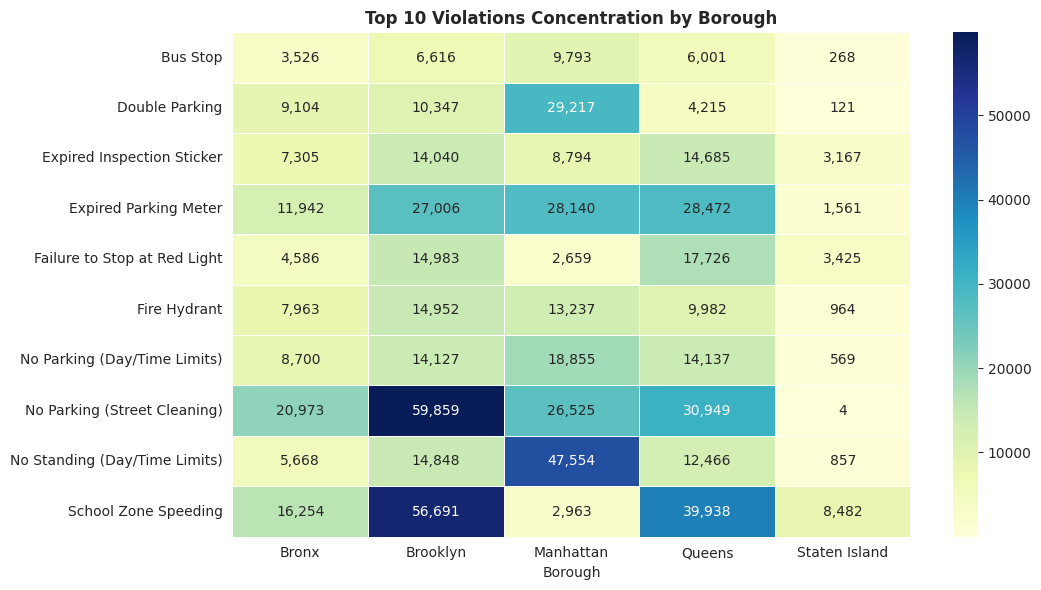

In [49]:
plt.figure(figsize=(11, 6))
sns.heatmap(violation_borough_pivot, annot=True, fmt=',d', cmap='YlGnBu', linewidths=0.5)
plt.title('Top 10 Violations Concentration by Borough', fontweight='bold')
plt.xlabel('Borough')
plt.ylabel('')
plt.tight_layout()
plt.show()

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>Manhattan = Commercial & Congestion Violations: Manhattan overwhelmingly leads in No Standing (47,554) and Double Parking (29,217)—classic signs of commercial delivery trucks and dense business traffic. Conversely, Manhattan has very few School Zone Speeding (2,963) and Red Light (2,659) tickets, likely because heavy traffic congestion makes speeding difficult. 
</div>


<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>Brooklyn & Queens = Residential & Camera Enforcement: Brooklyn dominates Street Cleaning (59,859) and School Zone Speeding (56,691). Queens also sees massive camera-enforced violations, ranking second in School Zone Speeding (39,938) and leading the city in Failure to Stop at Red Light (17,726).
</div>


<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>Staten Island's Unique Profile: Unlike the dense urban boroughs, Staten Island has virtually zero Street Cleaning tickets (only 4), with School Zone Speeding (8,482) standing out as its primary violation.
</div>

### Vehicle Profiles: Which vehicle makes, body types, and plate types (Commercial vs. Passenger) receive the most tickets?

In [50]:
make_summary = (
    df.groupby('Vehicle Make', observed=True)['Summons Number']
    .count()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name='Ticket_Count')
)
make_summary['Percentage'] = (make_summary['Ticket_Count'] / len(df) * 100).round(2)
print("Top 10 Vehicle Makes")
display(make_summary)

Top 10 Vehicle Makes


,Vehicle Make,Ticket_Count,Percentage
0,FORD,115159,11.80
1,TOYOT,109327,11.20
2,HONDA,97812,10.02
3,NISSA,83074,8.51
4,CHEVR,64004,6.56
5,FRUEH,39088,4.01
6,ME/BE,34979,3.58
7,BMW,34072,3.49
8,DODGE,33532,3.44
9,JEEP,31383,3.22


In [51]:
body_summary = (
    df.groupby('Vehicle Body Type', observed=True)['Summons Number']
    .count()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name='Ticket_Count')
)
body_summary['Percentage'] = (body_summary['Ticket_Count'] / len(df) * 100).round(2)
print(" Top 10 Vehicle Body Types")
display(body_summary)

 Top 10 Vehicle Body Types


,Vehicle Body Type,Ticket_Count,Percentage
0,SUBN,335277,34.36
1,4DSD,280855,28.78
2,VAN,127047,13.02
3,DELV,62228,6.38
4,SDN,38268,3.92
5,2DSD,25193,2.58
6,PICK,24115,2.47
7,REFG,9201,0.94
8,TRAC,6685,0.69
9,TAXI,5537,0.57


In [52]:
plate_summary = (
    df.groupby('Plate_category', observed=True)['Summons Number']
    .count()
    .sort_values(ascending=False)
    .reset_index(name='Ticket_Count')
)
plate_summary['Percentage'] = (plate_summary['Ticket_Count'] / len(df) * 100).round(2)
print("Plate Category Breakdown")
display(plate_summary)

Plate Category Breakdown


,Plate_category,Ticket_Count,Percentage
0,Passenger,722049,73.99
1,Commercial,165964,17.01
2,Other,87825,9.00


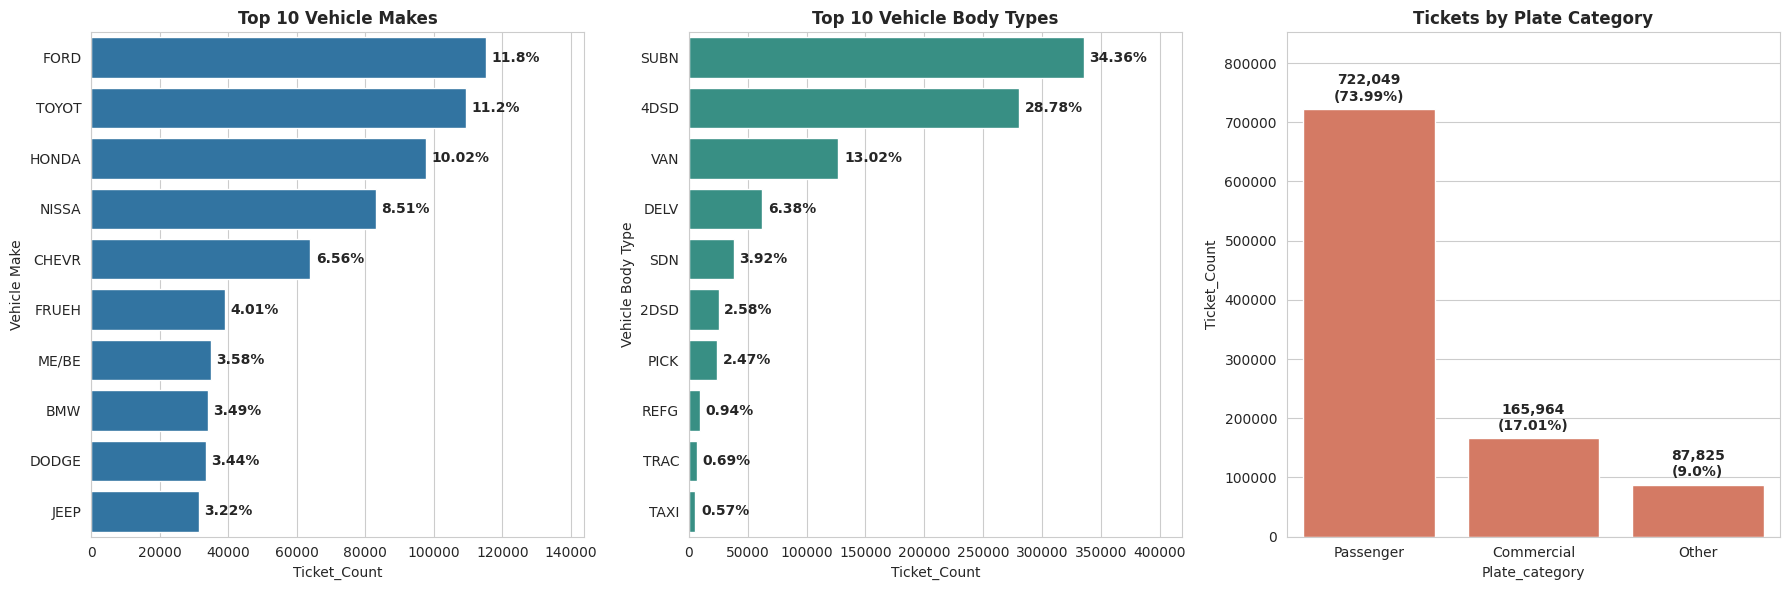

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Top 10 Makes
sns.barplot(data=make_summary, x='Ticket_Count', y='Vehicle Make', order=make_summary['Vehicle Make'], color='#1f77b4', ax=axes[0])
axes[0].bar_label(axes[0].containers[0], labels=[f"{p}%" for p in make_summary['Percentage']], padding=4, fontweight='bold')
axes[0].set_title('Top 10 Vehicle Makes', fontweight='bold')
axes[0].set_xlim(0, make_summary['Ticket_Count'].max() * 1.25)

# 2. Top 10 Body Types
sns.barplot(data=body_summary, x='Ticket_Count', y='Vehicle Body Type', order=body_summary['Vehicle Body Type'], color='#2a9d8f', ax=axes[1])
axes[1].bar_label(axes[1].containers[0], labels=[f"{p}%" for p in body_summary['Percentage']], padding=4, fontweight='bold')
axes[1].set_title('Top 10 Vehicle Body Types', fontweight='bold')
axes[1].set_xlim(0, body_summary['Ticket_Count'].max() * 1.25)

# 3. Plate Category
sns.barplot(data=plate_summary, x='Plate_category', y='Ticket_Count', order=plate_summary['Plate_category'], color='#e76f51', ax=axes[2])
axes[2].bar_label(axes[2].containers[0], labels=[f"{c:,}\n({p}%)" for c, p in zip(plate_summary['Ticket_Count'], plate_summary['Percentage'])], padding=4, fontweight='bold')
axes[2].set_title('Tickets by Plate Category', fontweight='bold')
axes[2].set_ylim(0, plate_summary['Ticket_Count'].max() * 1.18)

plt.tight_layout()
plt.show()

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>Top Vehicle Makes: Ford leads with 11.8% of all tickets, followed closely by Toyota (11.2%), Honda (10.02%), and Nissan (8.51%). While these passenger brands dominate largely due to their high market share on NYC roads, the presence of Fruehauf (FRUEH) at 4.01%—a major commercial truck/trailer manufacturer—highlights the heavy impact of commercial freight.
</div>

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>Dominant Body Types: Suburbans/SUVs (SUBN) account for 34.36% of violations, followed by 4-Door Sedans (4DSD) at 28.78%. Together, these two passenger body types represent 63.14% of all tickets. Meanwhile, Vans (VAN: 13.02%) and Delivery Trucks (DELV: 6.38%) combine for 19.4%, underscoring the parking challenges faced by commercial delivery fleets
</div>

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>Plate Categories (Passenger vs. Commercial): Passenger plates receive the vast majority of tickets at 722,049 (73.99%). Commercial plates account for 165,964 tickets (17.01%), and Other plate types make up 87,825 (9.0%)
</div>

### Local vs. Out-of-State: What proportion of tickets go to NY residents compared to out-of-state drivers?

In [54]:
ny_summary = (
    df.groupby('Is_NY_State', observed=True)['Summons Number']
    .count()
    .sort_values(ascending=False)
    .reset_index(name='Ticket_Count')
)
ny_summary['Percentage'] = (ny_summary['Ticket_Count'] / len(df) * 100).round(2)

print("NY Residents vs. Out-of-State ")
display(ny_summary)

NY Residents vs. Out-of-State 


,Is_NY_State,Ticket_Count,Percentage
0,NY (Local),765652,78.46
1,Out-of-State,210186,21.54


In [55]:
out_of_state_df = df[(df['Registration State'] != 'NY') & (df['Registration State'] != '99')]

top_out_states = (
    out_of_state_df.groupby('Registration State', observed=True)['Summons Number']
    .count()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name='Ticket_Count')
)
top_out_states['Percentage of Total'] = (top_out_states['Ticket_Count'] / len(df) * 100).round(2)

print("Top 10 Out-of-State Drivers ")
display(top_out_states)

Top 10 Out-of-State Drivers 


,Registration State,Ticket_Count,Percentage of Total
0,NJ,83812,8.59
1,PA,25665,2.63
2,FL,12958,1.33
3,CT,12851,1.32
4,MA,7715,0.79
5,IN,7367,0.75
6,VA,6491,0.67
7,MD,5621,0.58
8,NC,5112,0.52
9,IL,3454,0.35


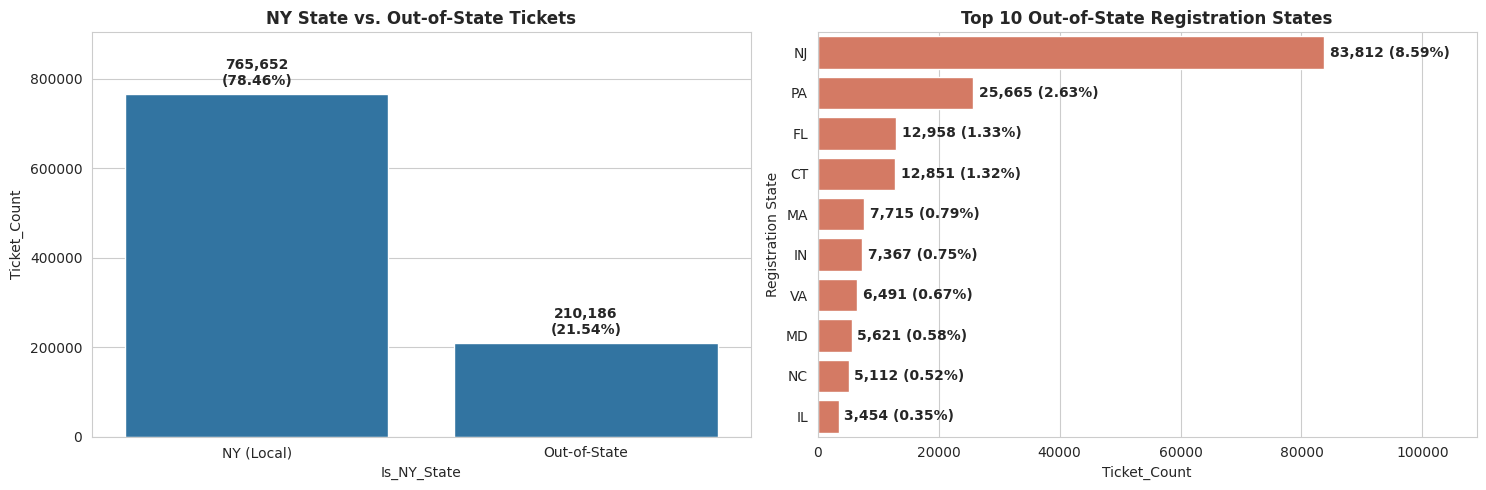

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. NY vs Out-of-State
sns.barplot(
    data=ny_summary, x='Is_NY_State', y='Ticket_Count',
    order=ny_summary['Is_NY_State'], color='#1f77b4', ax=axes[0]
)
labels_ny = [f"{c:,}\n({p}%)" for c, p in zip(ny_summary['Ticket_Count'], ny_summary['Percentage'])]
axes[0].bar_label(axes[0].containers[0], labels=labels_ny, padding=4, fontweight='bold')
axes[0].set_title('NY State vs. Out-of-State Tickets', fontweight='bold')
axes[0].set_ylim(0, ny_summary['Ticket_Count'].max() * 1.18)

# 2. Top 10 Out-of-State Drivers
sns.barplot(
    data=top_out_states, x='Ticket_Count', y='Registration State',
    order=top_out_states['Registration State'], color='#e76f51', ax=axes[1]
)
labels_out = [f"{c:,} ({p}%)" for c, p in zip(top_out_states['Ticket_Count'], top_out_states['Percentage of Total'])]
axes[1].bar_label(axes[1].containers[0], labels=labels_out, padding=4, fontweight='bold')
axes[1].set_title('Top 10 Out-of-State Registration States', fontweight='bold')
axes[1].set_xlim(0, top_out_states['Ticket_Count'].max() * 1.3)

plt.tight_layout()
plt.show()

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>NY Residents Dominate: Local New York drivers receive the vast majority of parking tickets at 765,652 (78.46%), while Out-of-State drivers account for a significant 210,186 tickets (21.54%)—meaning roughly 1 in every 5 tickets goes to a non-NY vehicle.
</div>

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Tri-State Commuters Lead Out-of-State Volume: New Jersey (NJ) overwhelmingly leads all out-of-state registrations with 83,812 tickets (8.59% of the entire dataset), followed by Pennsylvania (PA: 25,665 | 2.63%) and Connecticut (CT: 12,851 | 1.32%). This reflects the massive daily commuter and commercial freight traffic flowing into NYC from neighboring states.
</div>

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>Notable Non-Neighboring States: Florida (FL: 12,958 | 1.33%) ranks third among out-of-state drivers, while Indiana (IN: 7,367 | 0.75%) also appears in the top 6—a common pattern in NYC data driven by rental cars, commercial fleets, and leased vehicles registered in those states.
</div>

### Enforcement Agencies: Which agencies issue the majority of tickets, and how does their activity shift during the day?


In [57]:
agency_summary = (
    df.groupby('Issuing Agency', observed=True)['Summons Number']
    .count()
    .sort_values(ascending=False)
    .head(6)
    .reset_index(name='Ticket_Count')
)
agency_summary['Percentage'] = (agency_summary['Ticket_Count'] / len(df) * 100).round(2)

print(" Top Issuing Agencies")
display(agency_summary)

 Top Issuing Agencies


,Issuing Agency,Ticket_Count,Percentage
0,T,697821,71.51
1,V,180009,18.45
2,P,68986,7.07
3,S,26339,2.70
4,X,1763,0.18
5,K,665,0.07


In [58]:
top_4_agencies = agency_summary['Issuing Agency'].head(4).tolist()

agency_hour_pivot = pd.pivot_table(
    df[df['Issuing Agency'].isin(top_4_agencies)],
    index='Violation Hour',
    columns='Issuing Agency',
    values='Summons Number',
    aggfunc='count',
    observed=True
).fillna(0).astype(int)

print("Hourly Activity of Top 4  Agencies ")
display(agency_hour_pivot.head(10))

Hourly Activity of Top 4  Agencies 


Issuing Agency,P,S,T,V
Violation Hour,,,,
0.0,2086,447,0,816
1.0,3120,1180,3737,576
2.0,2616,733,3604,343
3.0,2030,780,2652,378
4.0,1443,138,618,407
5.0,1297,57,5684,615
6.0,1418,72,19214,1144
7.0,2005,4228,36580,5485
8.0,4365,6314,65300,15292


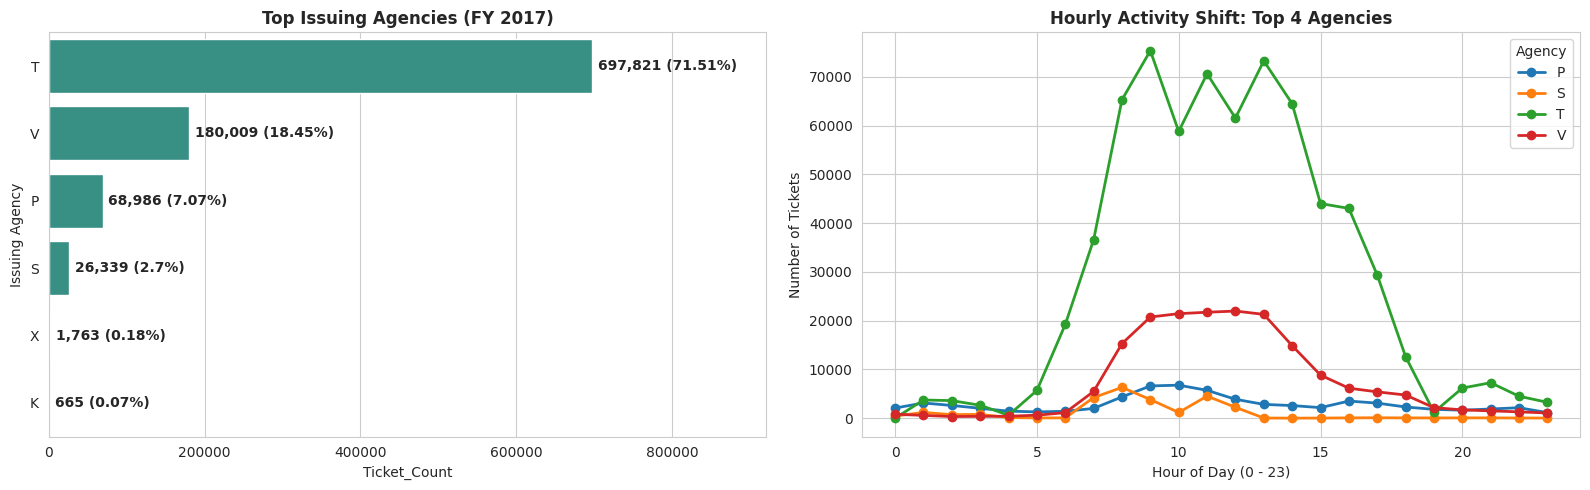

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(
    data=agency_summary, x='Ticket_Count', y='Issuing Agency',
    order=agency_summary['Issuing Agency'], color='#2a9d8f', ax=axes[0]
)
labels = [f"{c:,} ({p}%)" for c, p in zip(agency_summary['Ticket_Count'], agency_summary['Percentage'])]
axes[0].bar_label(axes[0].containers[0], labels=labels, padding=4, fontweight='bold')
axes[0].set_title('Top Issuing Agencies (FY 2017)', fontweight='bold')
axes[0].set_xlim(0, agency_summary['Ticket_Count'].max() * 1.32)

agency_hour_pivot.plot(kind='line', marker='o', linewidth=2, ax=axes[1])
axes[1].set_title('Hourly Activity Shift: Top 4 Agencies', fontweight='bold')
axes[1].set_xlabel('Hour of Day (0 - 23)')
axes[1].set_ylabel('Number of Tickets')
axes[1].legend(title='Agency')

plt.tight_layout()
plt.show()

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>Traffic (T) Dominates Enforcement: NYPD Traffic (T) issues the overwhelming majority of tickets at 697,821 (71.51%). Department of Transportation (V)—which operates automated speed and red-light cameras—ranks second with 180,009 tickets (18.45%), followed by Police (P: 68,986 | 7.07%) and Sanitation (S: 26,339 | 2.7%). Together, these top 4 agencies account for 99.73% of all tickets.
</div>

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>Traffic (T) Multi-Peak Daytime Shift: Agency T ramps up sharply at 6:00 AM, hitting three major peaks at 9:00 AM (~75K), 11:00 AM (~70.5K), and 1:00 PM (~73K) before declining steadily through the afternoon, with a small evening bump around 8:00–9:00 PM.
</div>

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>DOT Cameras (V) Mirror School/Commute Hours: Agency V rises at 7:00 AM, maintains a steady high plateau between 9:00 AM and 1:00 PM (~21K–22K per hour), and tapers off after 2:00 PM—aligning closely with active school zone camera hours.
</div>

<div style="background-color: #FFFBEB; padding: 14px 18px; border-radius: 8px; border-left: 5px solid #F7B801; color: #1E293B; font-family: 'Segoe UI', sans-serif; font-size: 14px;">
    <b style="color: #B45309;">💡 Key Insight:</b>Sanitation (S) & Police (P) Distinct Patterns: Sanitation (S) operates almost exclusively in a tight morning window—peaking at 8:00 AM and 11:00 AM before dropping to virtually zero after 1:00 PM, directly reflecting morning street-cleaning schedules. Police (P) maintains a lower, steadier presence throughout the day (peaking modestly around 9:00–10:00 AM), remaining active even during overnight hours.
</div>

<div style="background-color: #0B1F3A; padding: 12px 20px; border-radius: 8px; border-left: 6px solid #F7B801; color: #FFFFFF; font-family: 'Segoe UI', sans-serif;">
    <h2 style="margin: 0; font-size: 20px; color: #FFFFFF;">06 | Key Insights & Business Recommendations</h2>
</div>

<div style="font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; line-height: 1.7; color: #2b2d42;">

  <!-- Executive Summary: Key Insights -->
  <div style="background-color: #f8fafc; border-left: 6px solid #1d3557; border-radius: 8px; padding: 20px 25px; margin-bottom: 22px; box-shadow: 0 2px 6px rgba(0,0,0,0.06);">
    <h2 style="margin-top: 0; color: #1d3557; font-size: 20px; border-bottom: 1px solid #e2e8f0; padding-bottom: 10px;">
      📌 Executive Summary: Key Insights (FY 2017 — 1M Sample)
    </h2>
    <ul style="padding-left: 20px; margin-bottom: 0;">
      <li style="margin-bottom: 8px;">
        <strong>Peak Enforcement Windows:</strong> Violations peak on <strong>Thursday (~176K)</strong> and <strong>Friday (~173K)</strong>, with <strong>weekday mornings (6:00–11:00 AM)</strong> as the highest-risk window and <strong>9:00 AM (~107K)</strong> as the busiest hour. Seasonally, volume peaks in <strong>May (~95K)</strong> and dips in <strong>July (~65K)</strong> and <strong>December (~72K)</strong>.
      </li>
      <li style="margin-bottom: 8px;">
        <strong>Geographic Concentration:</strong> <strong>Manhattan (32.87%)</strong>, <strong>Brooklyn (28.55%)</strong>, and <strong>Queens (23.23%)</strong> account for <strong>84.65%</strong> of all parking violations citywide.
      </li>
      <li style="margin-bottom: 8px;">
        <strong>Distinct Borough Profiles:</strong> <strong>Manhattan</strong> leads in commercial congestion (<em>No Standing: 47,554</em>; <em>Double Parking: 29,217</em>), <strong>Brooklyn</strong> leads in <em>Street Cleaning (59,859)</em> and <em>School Zone Speeding (56,691)</em>, <strong>Queens</strong> leads in <em>Red Light (17,726)</em>, and <strong>Staten Island</strong> has virtually zero Street Cleaning tickets (<em>4</em>).
      </li>
      <li style="margin-bottom: 8px;">
        <strong>Top Violation Drivers:</strong> <em>Street Cleaning (14.22%)</em>, <em>School Zone Speeding (12.74%)</em>, and <em>Expired Parking Meters (9.96%)</em> lead the list; the top 10 codes represent <strong>73.55%</strong> of all tickets.
      </li>
      <li style="margin-bottom: 8px;">
        <strong>Vehicle & Driver Demographics:</strong> <strong>Passenger</strong> plates make up <strong>73.99%</strong> and <strong>Commercial</strong> plates <strong>17.01%</strong> (with Vans & Delivery Trucks at <strong>19.4%</strong>). Roughly <strong>1 in 5 tickets (21.54%)</strong> goes to <strong>Out-of-State</strong> drivers, led by <strong>NJ (8.59%)</strong> and <strong>PA (2.63%)</strong>.
      </li>
      <li>
        <strong>Enforcement Agency Dynamics:</strong> <strong>NYPD Traffic (T)</strong> issues <strong>71.51%</strong> of all tickets (peaking at 9 AM, 11 AM, and 1 PM), while <strong>DOT automated cameras (V)</strong> issue <strong>18.45%</strong> (steady plateau from 9 AM to 1 PM).
      </li>
    </ul>
  </div>

  <!-- Actionable Business Recommendations -->
  <div style="background-color: #f0fdf4; border-left: 6px solid #2a9d8f; border-radius: 8px; padding: 20px 25px; box-shadow: 0 2px 6px rgba(0,0,0,0.06);">
    <h2 style="margin-top: 0; color: #1b6d63; font-size: 20px; border-bottom: 1px solid #d1fae5; padding-bottom: 10px;">
      💡 Actionable Business Recommendations
    </h2>
    <ol style="padding-left: 20px; margin-bottom: 0;">
      <li style="margin-bottom: 8px;">
        <strong>Optimize Patrol Staffing Around Peak Windows:</strong> Align <strong>NYPD Traffic (T)</strong> deployments with the <strong>8:00 AM – 2:00 PM weekday surge</strong> (Tue–Fri) across Manhattan, Brooklyn, and Queens, while reducing low-volume overnight and Sunday patrols.
      </li>
      <li style="margin-bottom: 8px;">
        <strong>Incentivize Off-Hour Commercial Deliveries in Manhattan:</strong> Expand dedicated loading zones and offer incentives for overnight freight deliveries to curb Manhattan's heavy <em>No Standing</em> and <em>Double Parking</em> congestion.
      </li>
      <li style="margin-bottom: 8px;">
        <strong>Target Safety & Camera Enforcement in Outer Boroughs:</strong> Expand automated <strong>DOT (V)</strong> camera coverage and traffic-calming measures in <strong>Brooklyn, Queens, and Staten Island</strong>, where speeding and red-light violations dominate.
      </li>
      <li style="margin-bottom: 8px;">
        <strong>Promote Digital Compliance Tools:</strong> Integrate automated push alerts for <em>Street Cleaning (14.22%)</em> schedules and mobile extensions for <em>Parking Meters (9.96%)</em> to boost driver compliance.
      </li>
      <li>
        <strong>Strengthen Out-of-State Fine Collection:</strong> Enhance Tri-State DMV reciprocity agreements (especially <strong>NJ</strong> and <strong>PA</strong>) and streamline automated billing with major rental/commercial fleet operators to secure revenue from the <strong>21.54%</strong> out-of-state share.
      </li>
    </ol>
  </div>

</div>